# Scalar Field Effective Resolution Demo

This notebook demonstrates the **scalar field effective resolution** capability, which extends the wind-based diagnostic to work with any 2D atmospheric or oceanic variable.

## Overview

The scalar field analysis enables effective resolution computation for:

- **Temperature** → resolved thermal gradient scales
- **Geopotential height** → resolved pressure system scales
- **Precipitation** → resolved precipitation pattern scales
- **Sea surface temperature** → resolved SST scales
- **Any 2D atmospheric or oceanic field**

## Key Differences from Wind-Based Analysis

| Aspect | Wind Analysis | Scalar Field Analysis |
|--------|--------------|----------------------|
| **Input** | u and v winds (Dataset) | Any single 2D field (DataArray) |
| **Spectrum** | Kinetic energy (rotational + divergent) | Power spectrum (variance) |
| **Transform** | Vorticity/divergence decomposition | Direct field transform |
| **Detection** | 2-of-3 confirmation rule | Single spectrum |
| **Interpretation** | Resolved kinetic energy scales | Resolved variance scales |
| **Use case** | Atmospheric dynamics | Any 2D field |

## Reference

New capability added to support Klaver et al. (2020) methodology for any scalar field, not just winds.

Klaver, R., Haarsma, R., Vidale, P. L., & Hazeleger, W. (2020). Effective resolution in high resolution global atmospheric models for climate studies. *Atmospheric Science Letters*, 21, e952. https://doi.org/10.1002/asl.952

## 1. Setup and Imports

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd

from pcmdi_metrics.effective_resolution import (
    compute_effective_resolution,
    compute_effective_resolution_scalar,  # NEW scalar field API
    compute_power_spectrum_timeseries,  # NEW for direct spectral analysis\n)
from pcmdi_metrics.effective_resolution.lib import (
    plot_spectra_and_slope,
    representative_grid_box_distance,
)

%matplotlib inline
plt.rcParams["figure.dpi"] = 110

## 2. Generate Synthetic Data

We'll reuse the data generation functions from the main demo to create wind fields with prescribed spectral characteristics.

In [2]:
from pcmdi_metrics.effective_resolution.lib.ke_spectra import _legendre, EARTH_RADIUS


def random_coefficients(target_spectrum, rng, rsphere=EARTH_RADIUS):
    """Random vorticity/divergence coefficients whose power follows `target_spectrum`."""
    ell = np.arange(target_spectrum.size, dtype=float)
    ntrunc = ell.size - 1
    with np.errstate(divide="ignore", invalid="ignore"):
        variance = 2.0 * target_spectrum * ell * (ell + 1.0) / (rsphere**2 * (2 * ell + 1.0))
    variance[0] = 0.0

    coeffs = np.zeros((ntrunc + 1, ntrunc + 1), dtype=complex)
    coeffs[:, 0] = np.sqrt(variance) * rng.normal(size=ntrunc + 1)
    for m in range(1, ntrunc + 1):
        scale = np.sqrt(variance[m:] / 2.0)
        size = ntrunc + 1 - m
        coeffs[m:, m] = scale * (rng.normal(size=size) + 1j * rng.normal(size=size))
    return coeffs


def synthesize_wind(ke_rot, ke_div, lat, nlon, rng, rsphere=EARTH_RADIUS):
    """Inverse spherical-harmonic transform: (u, v) with the requested KE spectra."""
    ell = np.arange(ke_rot.size, dtype=float)
    ntrunc = ell.size - 1
    with np.errstate(divide="ignore", invalid="ignore"):
        to_potential = np.where(ell > 0, -(rsphere**2) / (ell * (ell + 1.0)), 0.0)[:, None]
    psi = to_potential * random_coefficients(ke_rot, rng)
    chi = to_potential * random_coefficients(ke_div, rng)

    mu = np.sin(np.deg2rad(lat))
    cosphi = np.cos(np.deg2rad(lat))
    u_f = np.zeros((lat.size, nlon // 2 + 1), dtype=complex)
    v_f = np.zeros_like(u_f)
    for m in range(ntrunc + 1):
        p, h = _legendre(m, ntrunc, mu)
        u_f[:, m] = (1j * m * (chi[m:, m][:, None] * p).sum(0)
                     - (psi[m:, m][:, None] * h).sum(0)) / rsphere
        v_f[:, m] = (1j * m * (psi[m:, m][:, None] * p).sum(0)
                     + (chi[m:, m][:, None] * h).sum(0)) / rsphere
    u = np.fft.irfft(u_f, n=nlon, axis=1) * nlon / cosphi[:, None]
    v = np.fft.irfft(v_f, n=nlon, axis=1) * nlon / cosphi[:, None]
    return u, v


def make_dummy_dataset(nlat=192, nlon=384, ntime=8, seed=0,
                       rolloff=(50.0, 70.0, 62.0), rms_wind=25.0, decay=40.0):
    """Create synthetic wind dataset with prescribed KE spectrum."""
    rng = np.random.default_rng(seed)
    lat = np.linspace(-90.0 + 90.0 / nlat, 90.0 - 90.0 / nlat, nlat)
    lon = np.arange(0.0, 360.0, 360.0 / nlon)

    ell = np.arange(nlat, dtype=float)
    with np.errstate(divide="ignore"):
        power_law = np.where(ell > 0, ell**-3.0, 0.0)

    def shaped(cut):
        return power_law * np.exp(-np.maximum(ell - cut, 0.0) / decay)

    div_cut, rot250_cut, rot500_cut = rolloff
    per_level = {
        250.0: (shaped(rot250_cut), 0.05 * shaped(div_cut)),
        500.0: (shaped(rot500_cut), 0.05 * shaped(div_cut)),
    }

    u = np.empty((ntime, 2, nlat, nlon))
    v = np.empty_like(u)
    for it in range(ntime):
        for ip, level in enumerate((250.0, 500.0)):
            ke_rot, ke_div = per_level[level]
            u_t, v_t = synthesize_wind(ke_rot, ke_div, lat, nlon, rng)
            norm = rms_wind / np.sqrt((u_t**2 + v_t**2).mean())
            u[it, ip], v[it, ip] = u_t * norm, v_t * norm

    time_coords = pd.date_range('2014-03-01', periods=ntime, freq='6h')
    
    ds = xr.Dataset(
        {"ua": (("time", "plev", "lat", "lon"), u),
         "va": (("time", "plev", "lat", "lon"), v)},
        coords={"time": ("time", time_coords),
                "plev": ("plev", np.array([25000.0, 50000.0])),
                "lat": ("lat", lat),
                "lon": ("lon", lon)},
    )
    ds["plev"].attrs.update(units="Pa", axis="Z")
    ds["lat"].attrs.update(units="degrees_north", axis="Y")
    ds["lon"].attrs.update(units="degrees_east", axis="X")
    ds["ua"].attrs.update(units="m s-1", long_name="Eastward wind")
    ds["va"].attrs.update(units="m s-1", long_name="Northward wind")
    return ds


# Create dummy dataset
ds = make_dummy_dataset()
print(f"Created dataset with shape: {ds['ua'].shape}")
print(f"Grid: {len(ds.lat)}×{len(ds.lon)} (roughly 1° resolution)")
print(f"Times: {len(ds.time)} timesteps")
print(f"Levels: {ds.plev.values / 100} hPa")

Created dataset with shape: (8, 2, 192, 384)
Grid: 192×384 (roughly 1° resolution)
Times: 8 timesteps
Levels: [250. 500.] hPa


## 3. Wind-Based Analysis (Baseline)

First, compute effective resolution using the full wind field (u+v) for comparison.

In [3]:
# Compute effective resolution from full wind field
metrics_wind, diagnostics_wind = compute_effective_resolution(
    ds,
    uvar="ua",
    vvar="va",
    levels=(250.0, 500.0),
    model="DUMMY-HR",
    member="r1i1p1f1",
)

result_wind = metrics_wind["DUMMY-HR"]["r1i1p1f1"]

print("Wind-based analysis (u+v):")
print(f"  Effective wavenumber: l = {result_wind['effective_wavenumber']}")
print(f"  Effective resolution: L_eff = {result_wind['effective_resolution_km']:.1f} km")
print(f"  Grid box distance: L_box = {result_wind['grid_box_distance_km']:.1f} km")
print(f"  Resolution ratio: L_eff/L_box = {result_wind['resolution_ratio']:.2f}")
print(f"  Spectra steepening: {result_wind['n_spectra_steepening']} of 3")
print(f"  Detection: {result_wind['steepening_wavenumber']}")

Wind-based analysis (u+v):
  Effective wavenumber: l = 63.0
  Effective resolution: L_eff = 315.2 km
  Grid box distance: L_box = 134.0 km
  Resolution ratio: L_eff/L_box = 2.35
  Spectra steepening: 3 of 3
  Detection: {'div_250': 51.0, 'rot_250': 70.0, 'rot_500': 63.0}


## 4. Scalar Field Analysis (NEW)

Now analyze the **zonal wind (ua)** as a single scalar field using the new API.

### Key Differences in API Usage:

1. **Input**: `xr.DataArray` (single field) instead of `xr.Dataset` (multiple variables)
2. **Function**: `compute_effective_resolution_scalar()` instead of `compute_effective_resolution()`
3. **Level selection**: Already done (field is at single level)
4. **Time handling**: Automatic (averages if time dimension present)

### ⚠️ Important: Scientific Correctness - Time Averaging

**Critical Methodological Point**: When analyzing time-varying fields, it's essential to average **spectra**, not **fields**.

**Why This Matters:**

❌ **Incorrect Approach** (suppresses transient variance):
```python
# Wrong: average field first, then compute spectrum
field_mean = field.mean(dim='time')
spectrum = compute_power_spectrum(field_mean)
# Result: Loses small-scale transient fluctuations!
```

✅ **Correct Approach** (preserves transient variance):
```python
# Right: compute spectrum for each time, then average spectra
spectra = [compute_power_spectrum(field[t]) for t in times]
spectrum_mean = mean(spectra)
# Result: Preserves all variance correctly!
```

**Implementation in PMP:**

The `compute_effective_resolution_scalar()` function **automatically handles this correctly** by using `compute_power_spectrum_timeseries()` internally. You don't need to do anything special - just pass your time-varying field and it will:

1. Compute power spectrum for each timestep
2. Average the spectra (not the fields)
3. Follow Klaver et al. (2020) methodology exactly

**Reference**: This follows the methodology in Klaver et al. (2020) Appendix S3, which explicitly computes spectra for individual months then averages them. See [SCIENTIFIC_CORRECTNESS_FIX.md](SCIENTIFIC_CORRECTNESS_FIX.md) for technical details.

In [4]:
# Extract ua at 250 hPa as a DataArray
ua_250 = ds['ua'].sel(plev=25000)  # Shape: (time, lat, lon)

print(f"Input field: {ua_250.name}")
print(f"  Dimensions: {dict(ua_250.sizes)}")
print(f"  Will be time-averaged automatically")

# Compute effective resolution for this scalar field
metrics_scalar, diagnostics_scalar = compute_effective_resolution_scalar(
    ua_250,
    field_name='ua_250hPa',
    model='DUMMY-HR',
    member='r1i1p1f1'
)

result_scalar = metrics_scalar['DUMMY-HR']['r1i1p1f1']

print("\nScalar field analysis (u only):")
print(f"  Field name: {result_scalar['field_name']}")
print(f"  Analysis type: {result_scalar['analysis_type']}")
print(f"  Effective wavenumber: l = {result_scalar['effective_wavenumber']}")
if result_scalar['effective_resolution_km']:
    print(f"  Effective resolution: L_eff = {result_scalar['effective_resolution_km']:.1f} km")
    print(f"  Resolution ratio: L_eff/L_box = {result_scalar['resolution_ratio']:.2f}")
else:
    print(f"  No steepening detected")
print(f"  Detection: {result_scalar['steepening_wavenumber']}")

Input field: ua
  Dimensions: {'time': 8, 'lat': 192, 'lon': 384}
  Will be time-averaged automatically

Scalar field analysis (u only):
  Field name: ua_250hPa
  Analysis type: scalar_field
  Effective wavenumber: l = 68.0
  Effective resolution: L_eff = 292.2 km
  Resolution ratio: L_eff/L_box = 2.18
  Detection: {'ua_250hPa': 68.0}


/Users/lee1043/miniforge3/envs/pmp_devel_20260331/lib/python3.12/site-packages/pcmdi_metrics/effective_resolution/lib/spectral_slope.py:96: RuntimeWarning: divide by zero encountered in log
  log_l = np.log(ell)


## 5. Comparison: Wind vs Scalar Analysis

Compare the two approaches side-by-side:

In [5]:
comparison = pd.DataFrame({
    'Wind-based (u+v)': {
        'Effective wavenumber': result_wind['effective_wavenumber'],
        'Effective resolution (km)': round(result_wind['effective_resolution_km'], 1),
        'Resolution ratio': round(result_wind['resolution_ratio'], 2),
        'Grid box distance (km)': round(result_wind['grid_box_distance_km'], 1),
        'Analysis type': 'KE (rot + div)',
        'Spectra used': f"{result_wind['n_spectra_steepening']} of 3",
        'Detection method': '2-of-3 confirmation',
        'Upper limit': result_wind['is_upper_limit']
    },
    'Scalar (u only)': {
        'Effective wavenumber': result_scalar['effective_wavenumber'],
        'Effective resolution (km)': round(result_scalar['effective_resolution_km'], 1) if result_scalar['effective_resolution_km'] else None,
        'Resolution ratio': round(result_scalar['resolution_ratio'], 2) if result_scalar['resolution_ratio'] else None,
        'Grid box distance (km)': round(result_scalar['grid_box_distance_km'], 1),
        'Analysis type': result_scalar['analysis_type'],
        'Spectra used': '1 (power)',
        'Detection method': 'Single spectrum',
        'Upper limit': result_scalar['is_upper_limit']
    }
})

print(comparison.T.to_string())
print("\n" + "="*70)
print("Key observations:")
print("  • Different effective resolutions (single field vs full wind vector)")
print("  • Scalar uses power spectrum of variance")
print("  • Wind uses kinetic energy (rotational + divergent)")
print("  • Scalar simpler but less robust (no multi-spectrum confirmation)")

                 Effective wavenumber Effective resolution (km) Resolution ratio Grid box distance (km)   Analysis type Spectra used     Detection method Upper limit
Wind-based (u+v)                 63.0                     315.2             2.35                  134.0  KE (rot + div)       3 of 3  2-of-3 confirmation       False
Scalar (u only)                  68.0                     292.2             2.18                  134.0    scalar_field    1 (power)      Single spectrum       False

Key observations:
  • Different effective resolutions (single field vs full wind vector)
  • Scalar uses power spectrum of variance
  • Wind uses kinetic energy (rotational + divergent)
  • Scalar simpler but less robust (no multi-spectrum confirmation)


## 6. Visualize Spectra

Compare the spectral characteristics visually:

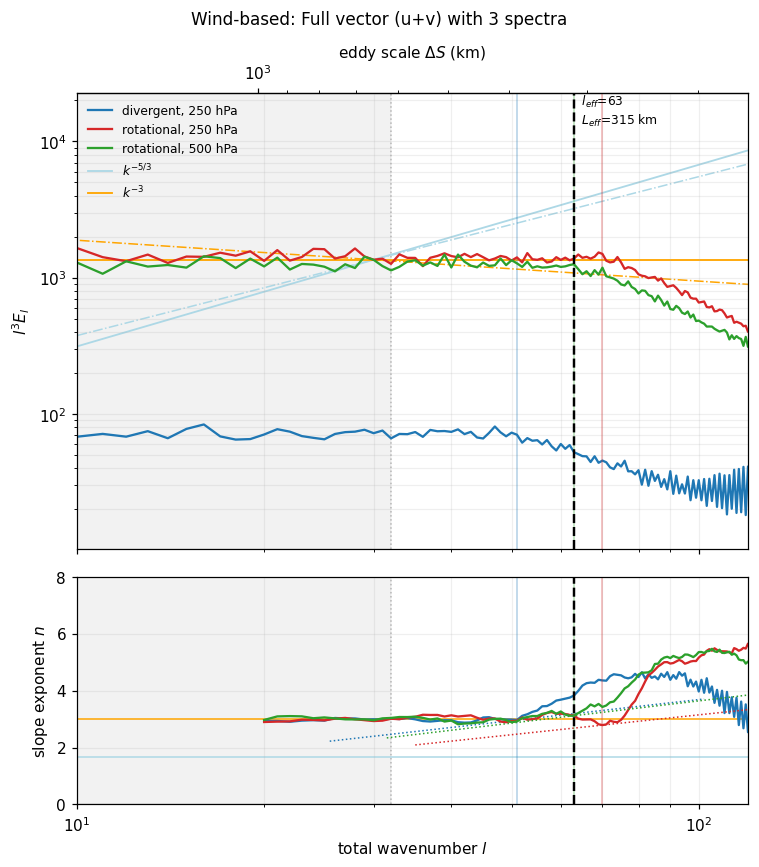

/Users/lee1043/miniforge3/envs/pmp_devel_20260331/lib/python3.12/site-packages/pcmdi_metrics/effective_resolution/lib/plot.py:316: RuntimeWarning: divide by zero encountered in power
  y_ref = anchor_y * (ell_ref / anchor_l) ** (


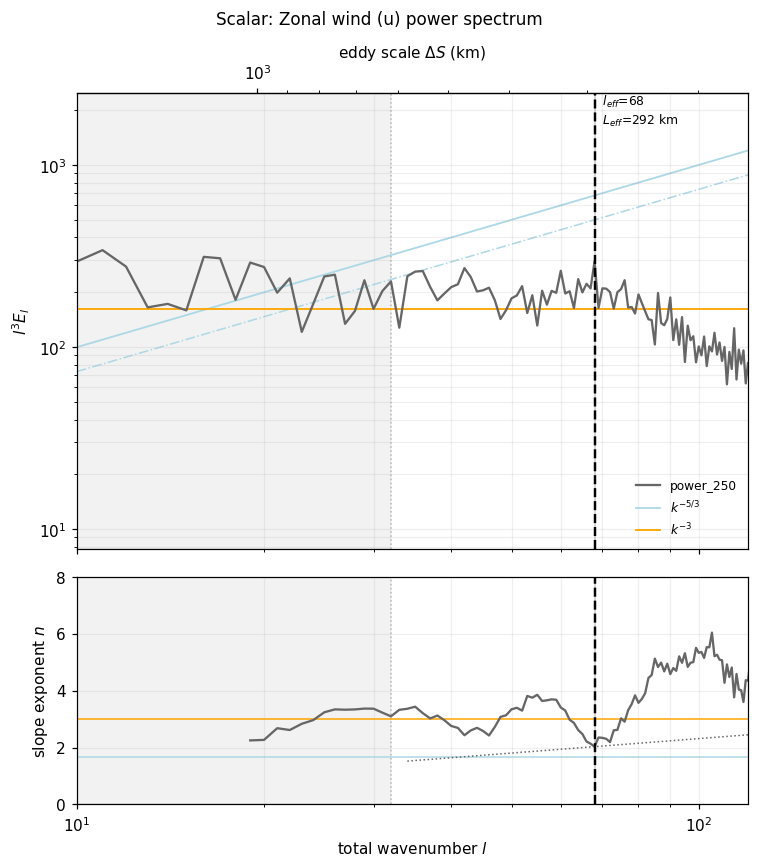


Visualization notes:
  • Top plot: Compensated spectrum (l³E_l)
  • Bottom plot: Spectral slope exponent n(l)
  • Wind shows 3 separate spectra (div_250, rot_250, rot_500)
  • Scalar shows single power spectrum

Note: Scalar diagnostics adapted with 'power_250' key to match plotting format


In [6]:
# Plot wind-based spectra (3 lines)
fig1 = plot_spectra_and_slope(
    diagnostics_wind,
    result_wind,
    xlim=(10, 120),
    title="Wind-based: Full vector (u+v) with 3 spectra"
)
plt.show()

# For scalar field, adapt diagnostics structure to match plotting function expectations
# The plotting function expects:
#   - slopes keys like "component_level" (e.g., "div_250", "rot_250")
#   - spectra structure: {level: {"ke_component": DataArray}}
# Scalar returns single spectrum, so we use "power_250" as the key
diagnostics_scalar_adapted = {
    "spectra": {250.0: {"ke_power": diagnostics_scalar["spectrum"]["power_spectrum"]}},
    "slopes": {"power_250": diagnostics_scalar["slope"]},
    "detections": {"power_250": diagnostics_scalar["detection"]},
}

# Plot scalar spectrum (1 line)
fig2 = plot_spectra_and_slope(
    diagnostics_scalar_adapted,
    result_scalar,
    xlim=(10, 120),
    title="Scalar: Zonal wind (u) power spectrum"
)
plt.show()

print("\nVisualization notes:")
print("  • Top plot: Compensated spectrum (l³E_l)")
print("  • Bottom plot: Spectral slope exponent n(l)")
print("  • Wind shows 3 separate spectra (div_250, rot_250, rot_500)")
print("  • Scalar shows single power spectrum")
print("\nNote: Scalar diagnostics adapted with 'power_250' key to match plotting format")

## 7. General Usage for Other Fields

The scalar field API works with any 2D atmospheric or oceanic variable:

### Supported Variables

- **Temperature** (`ta`): Resolved thermal gradient scales
- **Geopotential height** (`zg`): Resolved pressure system scales
- **Precipitation** (`pr`): Resolved precipitation pattern scales
- **Sea surface temperature** (`tos`): Resolved SST scales
- **Specific humidity** (`hus`): Resolved moisture scales
- **Any 2D field**: General spectral variance analysis

### Example Code Templates

In [7]:
# Example 1: Temperature at 500 hPa
# temp_500 = ds['ta'].sel(plev=50000)
# metrics_temp, diags_temp = compute_effective_resolution_scalar(
#     temp_500,
#     field_name='temperature_500hPa',
#     model='MODEL_NAME',
#     member='r1i1p1f1'
# )

# Example 2: Sea surface temperature (time-varying)
# sst = ds['tos']  # (time, lat, lon)
# metrics_sst, diags_sst = compute_effective_resolution_scalar(
#     sst,
#     field_name='SST',
#     model='MODEL_NAME'
# )
# # Automatically averages over time dimension

# Example 3: Precipitation
# pr = ds['pr'].sel(time=slice('2014-01', '2014-12'))
# metrics_pr, diags_pr = compute_effective_resolution_scalar(
#     pr,
#     field_name='precipitation',
#     model='MODEL_NAME'
# )

# Example 4: Geopotential height at 250 hPa
# zg_250 = ds['zg'].sel(plev=25000)
# metrics_zg, diags_zg = compute_effective_resolution_scalar(
#     zg_250,
#     field_name='geopotential_250hPa',
#     model='MODEL_NAME'
# )

print("API accepts:")
print("  ✓ xarray.DataArray with (lat, lon) or (time, lat, lon)")
print("  ✓ Automatically handles time averaging")
print("  ✓ Returns same structure as wind-based analysis")
print("  ✓ Works with any 2D field (temp, precip, SST, etc.)")

API accepts:
  ✓ xarray.DataArray with (lat, lon) or (time, lat, lon)
  ✓ Automatically handles time averaging
  ✓ Returns same structure as wind-based analysis
  ✓ Works with any 2D field (temp, precip, SST, etc.)


## 8. Summary

### Scalar Field Capability

✅ **Generalizes** wind diagnostic to any 2D variable  
✅ **Same methodology** (spherical harmonics, slope fitting, steepening)  
✅ **Consistent output** format for easy comparison  
✅ **Broader applications** (temp, precip, SST, any field)  

### Physical Interpretation

The "effective resolution" represents the scale below which **field variance** is artificially damped:

- **Temperature**: Smallest resolved thermal gradient scale
- **Geopotential**: Smallest resolved pressure system scale
- **Precipitation**: Smallest resolved precipitation pattern scale
- **SST**: Smallest resolved ocean surface feature scale
- **General**: Scales where variance begins dissipating due to numerical effects

### When to Use Scalar vs Wind Analysis

**Use scalar analysis when:**
- Analyzing non-wind variables (temp, precip, etc.)
- Wind data not available
- Comparing resolution across different field types
- Simpler single-spectrum approach desired

**Use wind-based analysis when:**
- Comprehensive atmospheric model evaluation
- Comparing with Klaver et al. (2020) reference values
- Want robust multi-spectrum confirmation
- Studying atmospheric dynamics specifically

### References

- **Main demo**: See `demo_effective_resolution.ipynb` for wind-based examples
- **Paper**: Klaver et al. (2020), doi:10.1002/asl.952